# 06 — Results Analysis & Visualization

Generează tabelele și graficele finale pentru capitolul de Results.

**Citește din:**
- `experiments/inceptionresnetv2_naive/tier{N}/results.json` (notebook 01)
- `experiments/inceptionresnetv2/tier{N}/B_lpft/results.json` (notebook 02)
- `experiments/inceptionresnetv2/tier{N}/C_optuna/best_params.json` (notebook 03+04)
- `experiments/inceptionresnetv2/tier{N}/D_final/test_results.json` (notebook 05)

**Output:**
- `summary/master_table.csv` — toate experimentele × tier-uri
- `summary/test_acc_comparison.png` — Naive vs LP-FT vs Optuna pe tier-uri
- `summary/per_source_evolution.png` — HAM vs BCN per tier
- `summary/confusion_matrices_grid.png` — toate CM-urile final eval
- `summary/per_class_breakdown.csv` — F1 per clasă × tier


## 1. Setup


In [14]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted


In [15]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
NAIVE_DIR = DRIVE_BASE / 'experiments' / 'inceptionresnetv2_naive'
EFNET_DIR = DRIVE_BASE / 'experiments' / 'inceptionresnetv2'
SUMMARY_DIR = EFNET_DIR / 'summary'
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

print(f'Naive dir:   {NAIVE_DIR.exists()} {NAIVE_DIR}')
print(f'EFNet dir:   {EFNET_DIR.exists()} {EFNET_DIR}')
print(f'Summary dir: {SUMMARY_DIR}')


Naive dir:   True /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2_naive
EFNet dir:   True /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2
Summary dir: /content/drive/MyDrive/Thesis/experiments/inceptionresnetv2/summary


## 2. Master table — toate experimentele × tier-uri


In [16]:
def load_naive(tier):
    p = NAIVE_DIR / f'tier{tier}' / 'results.json'
    if not p.exists():
        return None
    with open(p) as f:
        r = json.load(f)
    return r


def load_lpft(tier):
    p = EFNET_DIR / f'tier{tier}' / 'B_lpft' / 'results.json'
    if not p.exists():
        return None
    with open(p) as f:
        r = json.load(f)
    return r


def load_optuna(tier):
    p = EFNET_DIR / f'tier{tier}' / 'C_optuna' / 'best_params.json'
    if not p.exists():
        return None
    with open(p) as f:
        r = json.load(f)
    return r


def load_final(tier):
    p = EFNET_DIR / f'tier{tier}' / 'D_final' / 'test_results.json'
    if not p.exists():
        return None
    with open(p) as f:
        r = json.load(f)
    return r


# Build master table
rows = []
for tier in [1, 2, 3, 4, 5]:
    row = {'tier': tier}

    naive = load_naive(tier)
    if naive:
        row['naive_test_acc'] = naive['test']['accuracy'] * 100
        row['naive_test_f1'] = naive['test']['macro_f1']
    else:
        row['naive_test_acc'] = None
        row['naive_test_f1'] = None

    lpft = load_lpft(tier)
    if lpft:
        row['lpft_test_acc'] = lpft['test']['accuracy'] * 100
        row['lpft_test_f1'] = lpft['test']['macro_f1']
    else:
        row['lpft_test_acc'] = None
        row['lpft_test_f1'] = None

    optuna = load_optuna(tier)
    if optuna:
        row['optuna_best_val_acc'] = optuna['best_value'] * 100
    else:
        row['optuna_best_val_acc'] = None

    final = load_final(tier)
    if final:
        row['final_test_acc'] = final['overall']['accuracy'] * 100
        row['final_test_f1'] = final['overall']['macro_f1']
        for src in ['HAM10000', 'BCN_20000', 'MSK']:
            m = final['per_source'].get(src, {})
            if m.get('n_samples', 0) > 0:
                row[f'final_{src}_acc'] = m['accuracy'] * 100
                row[f'final_{src}_f1'] = m['macro_f1']

    rows.append(row)

master_df = pd.DataFrame(rows)
master_df.to_csv(SUMMARY_DIR / 'master_table.csv', index=False)
print(master_df.to_string(index=False, float_format=lambda x: f'{x:.3f}' if x is not None else 'N/A'))


 tier  naive_test_acc  naive_test_f1  lpft_test_acc  lpft_test_f1  optuna_best_val_acc  final_test_acc  final_test_f1  final_HAM10000_acc  final_HAM10000_f1  final_BCN_20000_acc  final_BCN_20000_f1  final_MSK_acc  final_MSK_f1
    1          46.956          0.333         50.736         0.362               46.447          43.295          0.322              58.787              0.435               32.524               0.240         32.184         0.155
    2          56.984          0.448         61.202         0.497                  NaN          53.164          0.397              61.192              0.404               47.492               0.357         52.874         0.267
    3          47.553          0.362         65.738         0.550                  NaN          55.074          0.404              60.356              0.386               51.780               0.383         45.977         0.233
    4          56.068          0.451         68.285         0.555                  NaN      

## 3. Test accuracy comparison: Naive vs LP-FT vs Final


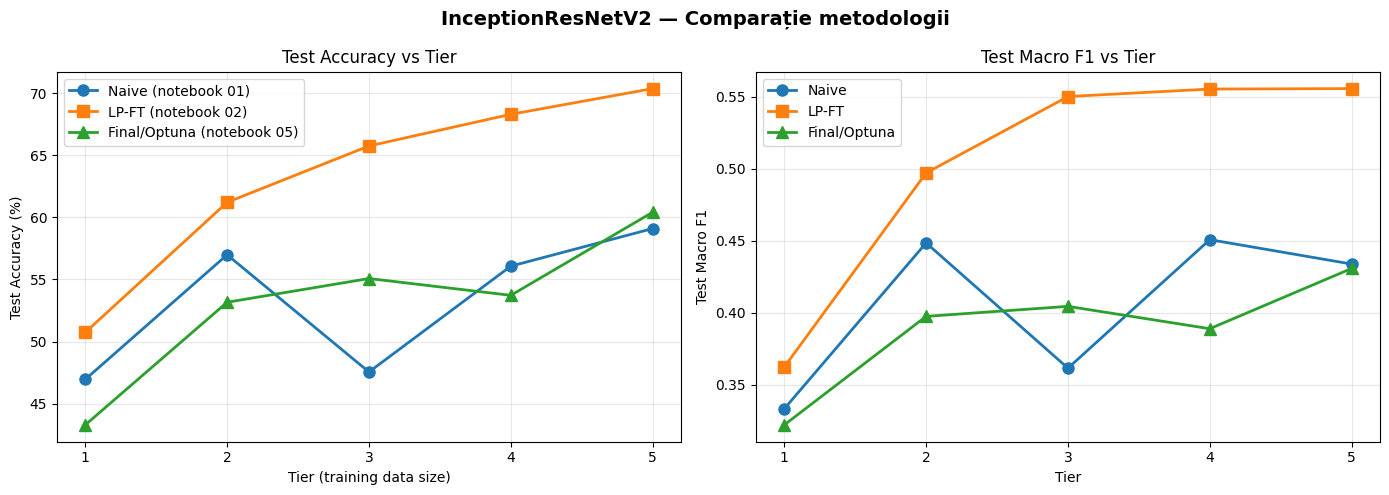

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tiers = [1, 2, 3, 4, 5]

# Subplot 1: Test Accuracy
ax = axes[0]
naive_acc = [r.get('naive_test_acc') for r in rows]
lpft_acc = [r.get('lpft_test_acc') for r in rows]
final_acc = [r.get('final_test_acc') for r in rows]

if any(v is not None for v in naive_acc):
    ax.plot(tiers, naive_acc, 'o-', label='Naive (notebook 01)', linewidth=2, markersize=8)
if any(v is not None for v in lpft_acc):
    ax.plot(tiers, lpft_acc, 's-', label='LP-FT (notebook 02)', linewidth=2, markersize=8)
if any(v is not None for v in final_acc):
    ax.plot(tiers, final_acc, '^-', label='Final/Optuna (notebook 05)', linewidth=2, markersize=8)

ax.set_xlabel('Tier (training data size)')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Test Accuracy vs Tier')
ax.set_xticks(tiers)
ax.legend()
ax.grid(True, alpha=0.3)

# Subplot 2: Test Macro F1
ax = axes[1]
naive_f1 = [r.get('naive_test_f1') for r in rows]
lpft_f1 = [r.get('lpft_test_f1') for r in rows]
final_f1 = [r.get('final_test_f1') for r in rows]

if any(v is not None for v in naive_f1):
    ax.plot(tiers, naive_f1, 'o-', label='Naive', linewidth=2, markersize=8)
if any(v is not None for v in lpft_f1):
    ax.plot(tiers, lpft_f1, 's-', label='LP-FT', linewidth=2, markersize=8)
if any(v is not None for v in final_f1):
    ax.plot(tiers, final_f1, '^-', label='Final/Optuna', linewidth=2, markersize=8)

ax.set_xlabel('Tier')
ax.set_ylabel('Test Macro F1')
ax.set_title('Test Macro F1 vs Tier')
ax.set_xticks(tiers)
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('InceptionResNetV2 — Comparație metodologii', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'test_acc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Per-source evolution (HAM vs BCN)


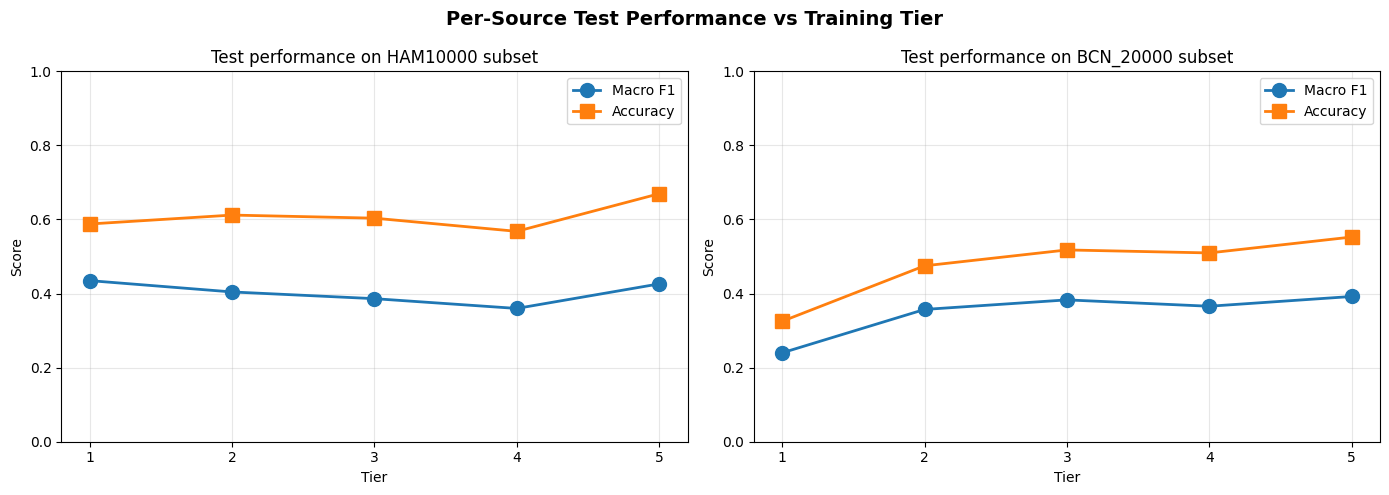

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sources = ['HAM10000', 'BCN_20000']
for src, ax in zip(sources, axes):
    f1_values = []
    acc_values = []
    for tier in tiers:
        final = load_final(tier)
        if final and src in final.get('per_source', {}):
            m = final['per_source'][src]
            if m.get('n_samples', 0) > 0:
                f1_values.append(m['macro_f1'])
                acc_values.append(m['accuracy'])
                continue
        f1_values.append(None)
        acc_values.append(None)

    valid_t = [t for t, v in zip(tiers, f1_values) if v is not None]
    valid_f1 = [v for v in f1_values if v is not None]
    valid_acc = [v for v, f in zip(acc_values, f1_values) if f is not None]

    if valid_f1:
        ax.plot(valid_t, valid_f1, 'o-', label='Macro F1', linewidth=2, markersize=10)
        ax.plot(valid_t, valid_acc, 's-', label='Accuracy', linewidth=2, markersize=10)

    ax.set_xlabel('Tier')
    ax.set_ylabel('Score')
    ax.set_title(f'Test performance on {src} subset')
    ax.set_xticks(tiers)
    ax.set_ylim(0, 1)
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle('Per-Source Test Performance vs Training Tier', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'per_source_evolution.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Confusion matrices grid (final eval)


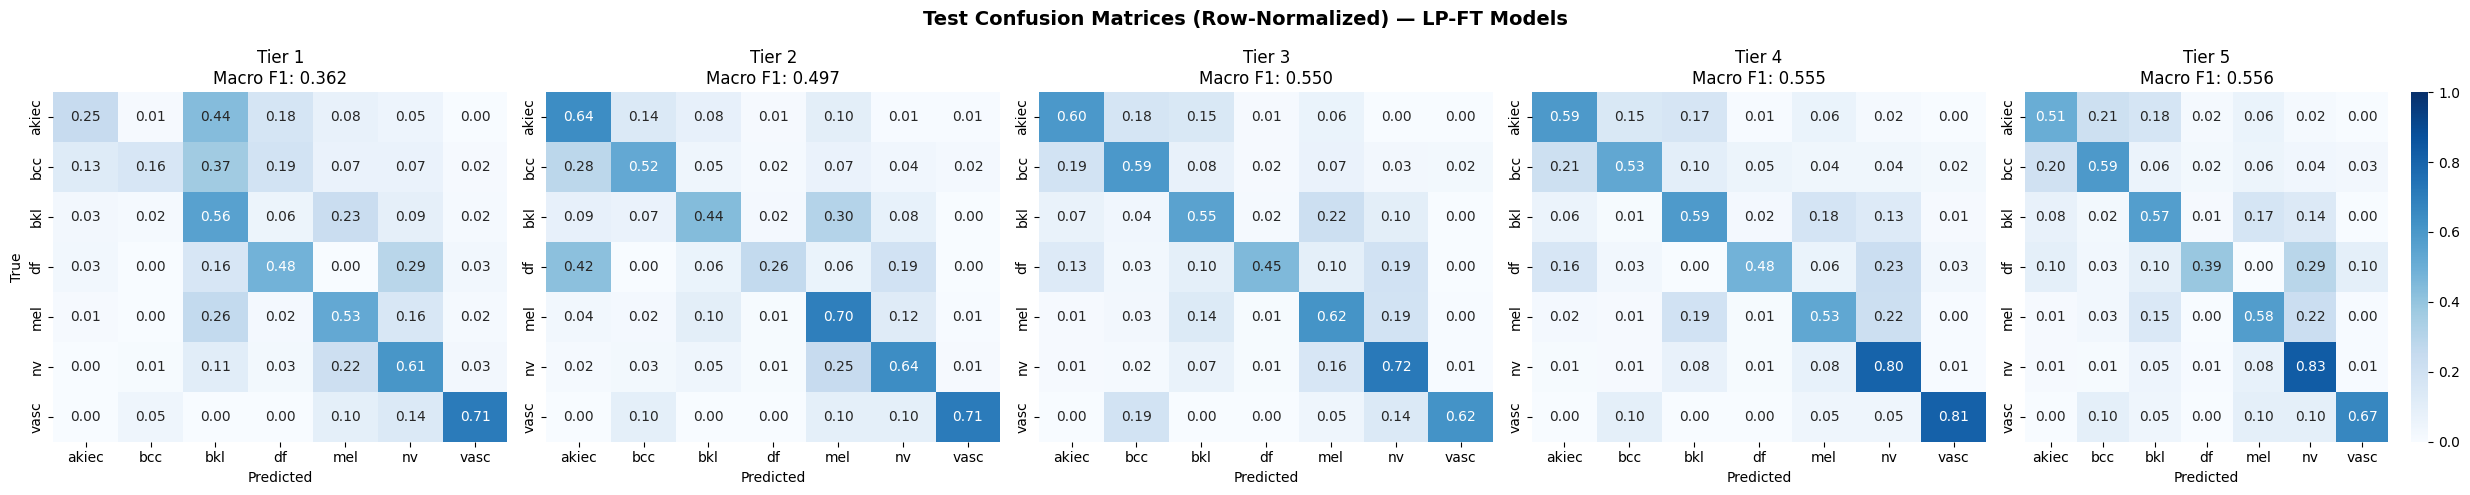

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

for tier_idx, tier in enumerate([1, 2, 3, 4, 5]):
    ax = axes[tier_idx]
    res = load_lpft(tier)

    if res and 'test' in res and 'confusion_matrix' in res['test']:
        cm = np.array(res['test']['confusion_matrix'])
        cm_norm = cm.astype(float) / (cm.sum(axis=1, keepdims=True) + 1e-9)

        sns.heatmap(
            cm_norm, annot=True, fmt='.2f',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=(tier_idx == 4),
        )
        ax.set_title(f'Tier {tier}\nMacro F1: {res["test"]["macro_f1"]:.3f}')
        ax.set_xlabel('Predicted')
        if tier_idx == 0:
            ax.set_ylabel('True')
    else:
        ax.text(0.5, 0.5, f'Tier {tier}\n(no data)', ha='center', va='center')
        ax.set_xticks([]); ax.set_yticks([])

plt.suptitle('Test Confusion Matrices (Row-Normalized) — LP-FT Models',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'confusion_matrices_grid.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Per-class F1 breakdown


Per-class F1 score per tier (LP-FT):
 tier  akiec   bcc   bkl    df   mel    nv  vasc
    1  0.300 0.260 0.330 0.160 0.440 0.710 0.340
    2  0.470 0.590 0.440 0.240 0.510 0.750 0.480
    3  0.520 0.650 0.460 0.380 0.530 0.790 0.510
    4  0.510 0.630 0.460 0.330 0.550 0.840 0.580
    5  0.450 0.660 0.490 0.380 0.580 0.850 0.480


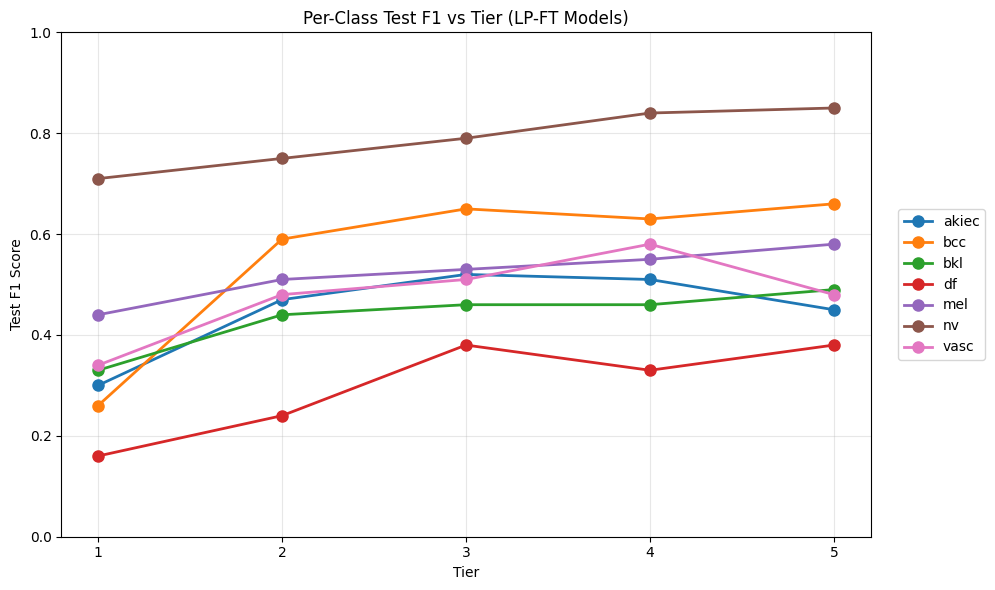

In [20]:
# Per-class F1 din classification_report (string parsing)
import re

def parse_classification_report(report_str):
    """Extract per-class F1 din output-ul sklearn classification_report."""
    metrics = {}
    for line in report_str.split('\n'):
        line = line.strip()
        for cls in CLASS_NAMES:
            if line.startswith(cls):
                parts = line.split()
                if len(parts) >= 4:
                    try:
                        metrics[cls] = float(parts[3])  # f1-score
                    except ValueError:
                        pass
    return metrics


per_class_rows = []
for tier in tiers:
    res = load_lpft(tier)
    if res and 'test' in res:
        report = res['test'].get('classification_report', '')
        per_class = parse_classification_report(report)
        row = {'tier': tier, **per_class}
        per_class_rows.append(row)

if per_class_rows:
    pc_df = pd.DataFrame(per_class_rows)
    pc_df.to_csv(SUMMARY_DIR / 'per_class_breakdown.csv', index=False)
    print('Per-class F1 score per tier (LP-FT):')
    print(pc_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    for cls in CLASS_NAMES:
        if cls in pc_df.columns:
            ax.plot(pc_df['tier'], pc_df[cls], 'o-', label=cls, linewidth=2, markersize=8)

    ax.set_xlabel('Tier')
    ax.set_ylabel('Test F1 Score')
    ax.set_title('Per-Class Test F1 vs Tier (LP-FT Models)')
    ax.set_xticks(tiers)
    ax.set_ylim(0, 1)
    ax.legend(loc='center right', bbox_to_anchor=(1.15, 0.5))
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(SUMMARY_DIR / 'per_class_evolution.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('No LP-FT results found')

## 7. Optuna best params — comparație Tier 1 vs Tier 5


In [21]:
print('Optuna best params comparison:\n')
print(f'{"Param":<25} {"Tier 1":>20} {"Tier 5":>20}')
print('-' * 70)

t1_opt = load_optuna(1)
t5_opt = load_optuna(5)

if t1_opt and t5_opt:
    all_keys = set(t1_opt['best_params'].keys()) | set(t5_opt['best_params'].keys())
    for k in sorted(all_keys):
        v1 = t1_opt['best_params'].get(k, 'N/A')
        v5 = t5_opt['best_params'].get(k, 'N/A')
        if isinstance(v1, float):
            v1 = f'{v1:.6f}' if v1 < 0.01 else f'{v1:.4f}'
        if isinstance(v5, float):
            v5 = f'{v5:.6f}' if v5 < 0.01 else f'{v5:.4f}'
        print(f'{k:<25} {str(v1):>20} {str(v5):>20}')

    print('-' * 70)
    print(f'{"best_val_accuracy":<25} {t1_opt["best_value"]:>20.4f} {t5_opt["best_value"]:>20.4f}')
elif t1_opt or t5_opt:
    found = t1_opt or t5_opt
    tier_label = 'Tier 1' if t1_opt else 'Tier 5'
    print(f'Only {tier_label} Optuna results found:')
    for k, v in found['best_params'].items():
        print(f'  {k}: {v}')
else:
    print('No Optuna results — run notebook 03 + 04 first')


Optuna best params comparison:

Param                                   Tier 1               Tier 5
----------------------------------------------------------------------
dense1_units                              1024                 2048
dense2_units                               512                  512
dropout                                 0.4681               0.3540
focal_gamma                             1.6856               1.7480
learning_rate                         0.000994             0.000016
rotation_max                                30                   30
zoom_range                              0.1328               0.1010
----------------------------------------------------------------------
best_val_accuracy                       0.4645               0.5629


## 7. Insight plots

### 7.1 Methodology contribution — grouped bars

Subliniază contribuția fiecărei etape (Naive / LP-FT / Optuna+Final) pe tier. Pentru InceptionResNetV2, **LP-FT depășește final-Optuna pe toate cele 5 tier-uri** — pattern invers față de EfficientNetV2B0. Acesta e un finding metodologic important: Optuna search-ul a regresat consistent față de baseline-ul LP-FT, probabil din cauza unui prior LR prea îngust care a convergent la valori extrem de mici (1.6e-5 la Tier 5).

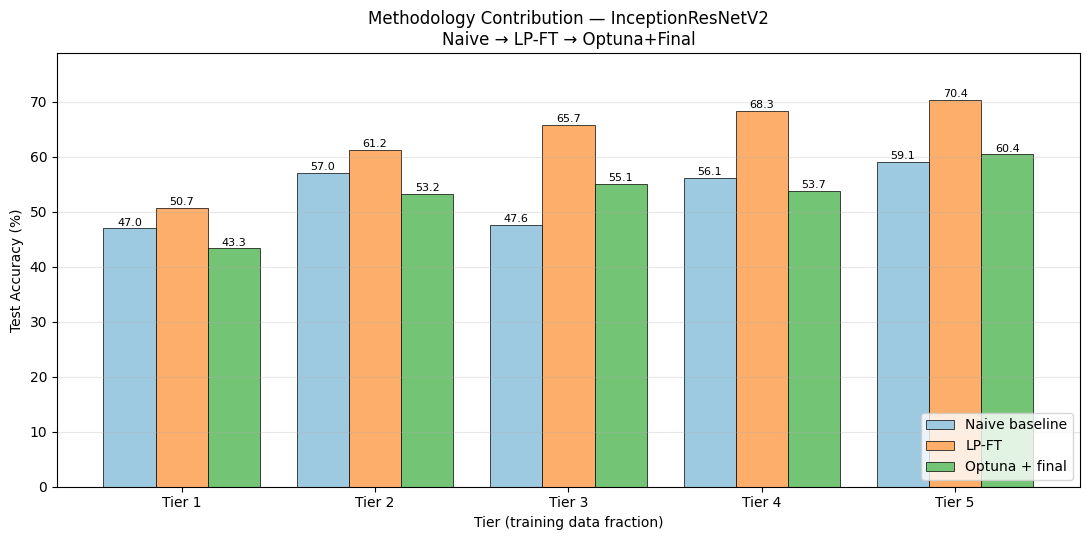

In [22]:
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(tiers))
width = 0.27

naive_acc = [r.get('naive_test_acc') or 0 for r in rows]
lpft_acc  = [r.get('lpft_test_acc')  or 0 for r in rows]
final_acc = [r.get('final_test_acc') or 0 for r in rows]

b1 = ax.bar(x - width, naive_acc, width, label='Naive baseline',
            color='#9ecae1', edgecolor='black', linewidth=0.5)
b2 = ax.bar(x,         lpft_acc,  width, label='LP-FT',
            color='#fdae6b', edgecolor='black', linewidth=0.5)
b3 = ax.bar(x + width, final_acc, width, label='Optuna + final',
            color='#74c476', edgecolor='black', linewidth=0.5)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 2), textcoords='offset points',
                        ha='center', fontsize=8)

ax.set_xlabel('Tier (training data fraction)')
ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Methodology Contribution — InceptionResNetV2\nNaive → LP-FT → Optuna+Final')
ax.set_xticks(x)
ax.set_xticklabels([f'Tier {t}' for t in tiers])
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
ymax = max(max(naive_acc), max(lpft_acc), max(final_acc))
ax.set_ylim(0, ymax * 1.12)
plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'methodology_bars.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.2 Per-class F1 heatmap (clase × tier-uri)

Vizual mult mai clar decât line plot-ul de la secțiunea 6: vezi imediat care clase rămân în zona slabă pe măsură ce crești datele (de ex. `df`) și care saturează rapid (`nv`).


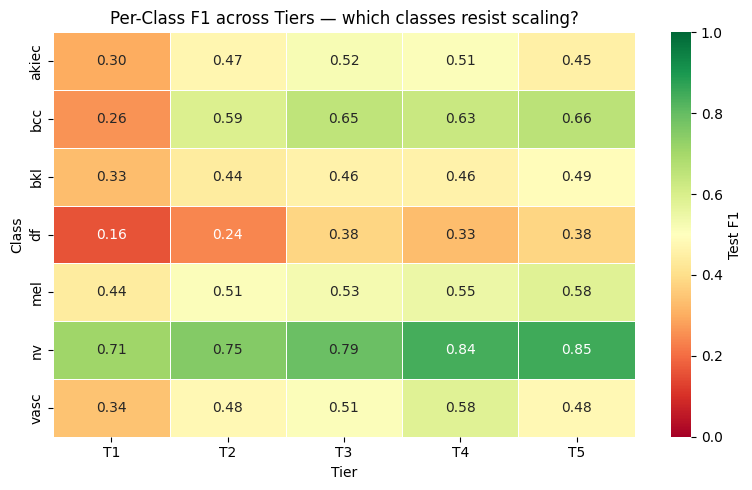

In [23]:
if per_class_rows:
    heat = pc_df.set_index('tier')[CLASS_NAMES].T  # rows=classes, cols=tiers

    fig, ax = plt.subplots(figsize=(8, 5))
    sns.heatmap(heat, annot=True, fmt='.2f', cmap='RdYlGn',
                vmin=0, vmax=1, cbar_kws={'label': 'Test F1'},
                linewidths=0.5, linecolor='white', ax=ax)
    ax.set_xlabel('Tier')
    ax.set_ylabel('Class')
    ax.set_title('Per-Class F1 across Tiers — which classes resist scaling?')
    ax.set_xticklabels([f'T{t}' for t in tiers], rotation=0)
    plt.tight_layout()
    plt.savefig(SUMMARY_DIR / 'per_class_heatmap.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Per-class data missing — run section 6 first.')


### 7.3 Domain gap — HAM vs BCN vs MSK

Banda colorată dintre HAM și BCN arată că adăugarea de date *nu* închide gap-ul de domeniu. Argument vizual direct pentru capitolul de critică / analiză a generalizării.


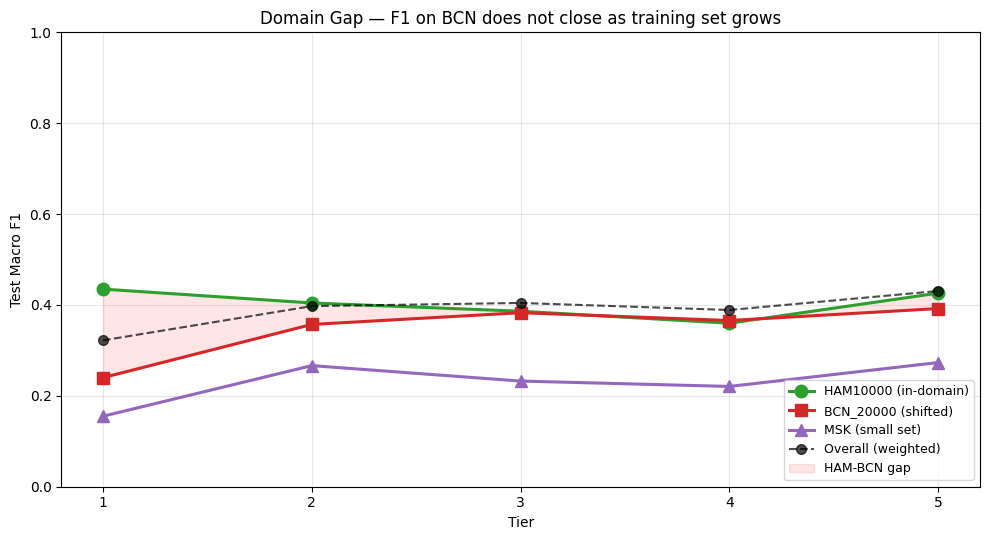

In [24]:
fig, ax = plt.subplots(figsize=(10, 5.5))

ham_f1 = [r.get('final_HAM10000_f1') for r in rows]
bcn_f1 = [r.get('final_BCN_20000_f1') for r in rows]
msk_f1 = [r.get('final_MSK_f1') for r in rows]
overall_f1 = [r.get('final_test_f1') for r in rows]

# Filter out None for plotting
def clean_pair(ts, vs):
    return [t for t, v in zip(ts, vs) if v is not None], [v for v in vs if v is not None]

t_ham, v_ham = clean_pair(tiers, ham_f1)
t_bcn, v_bcn = clean_pair(tiers, bcn_f1)
t_msk, v_msk = clean_pair(tiers, msk_f1)
t_ov,  v_ov  = clean_pair(tiers, overall_f1)

if v_ham:
    ax.plot(t_ham, v_ham, 'o-', label='HAM10000 (in-domain)',
            color='#2ca02c', linewidth=2.2, markersize=9)
if v_bcn:
    ax.plot(t_bcn, v_bcn, 's-', label='BCN_20000 (shifted)',
            color='#d62728', linewidth=2.2, markersize=9)
if v_msk:
    ax.plot(t_msk, v_msk, '^-', label='MSK (small set)',
            color='#9467bd', linewidth=2.2, markersize=9)
if v_ov:
    ax.plot(t_ov, v_ov, 'o--', label='Overall (weighted)',
            color='black', linewidth=1.5, markersize=7, alpha=0.7)

# Shade gap between HAM and BCN where both available
common = sorted(set(t_ham) & set(t_bcn))
if common:
    ham_dict = dict(zip(t_ham, v_ham))
    bcn_dict = dict(zip(t_bcn, v_bcn))
    gap_h = [ham_dict[t] for t in common]
    gap_b = [bcn_dict[t] for t in common]
    ax.fill_between(common, gap_h, gap_b, alpha=0.1, color='red', label='HAM-BCN gap')

ax.set_xlabel('Tier')
ax.set_ylabel('Test Macro F1')
ax.set_title('Domain Gap — F1 on BCN does not close as training set grows')
ax.set_xticks(tiers)
ax.set_ylim(0, 1)
ax.legend(loc='lower right', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'domain_gap.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.4 Stage deltas & class-support correlation

**Stânga:** cât adaugă (sau scade) fiecare etapă față de cea anterioară. Pentru InceptionResNetV2, `Δ LP-FT → Final (Optuna)` e **negativ pe toate tier-urile** — Optuna a regresat consistent față de LP-FT. `Δ Naive → LP-FT` rămâne pozitiv (LP-FT îmbunătățește baseline-ul replicat din Nawaz), iar `Δ Naive → Final` e mixt: tier-urile mici sunt sub Naive, doar Tier 5 reușește să depășească ușor.

**Dreapta:** corelația log între suportul de clasă în setul de antrenare și F1-ul realizat. Confirmă că imbalance-ul (nu metodologia) plafonează clasele rare.

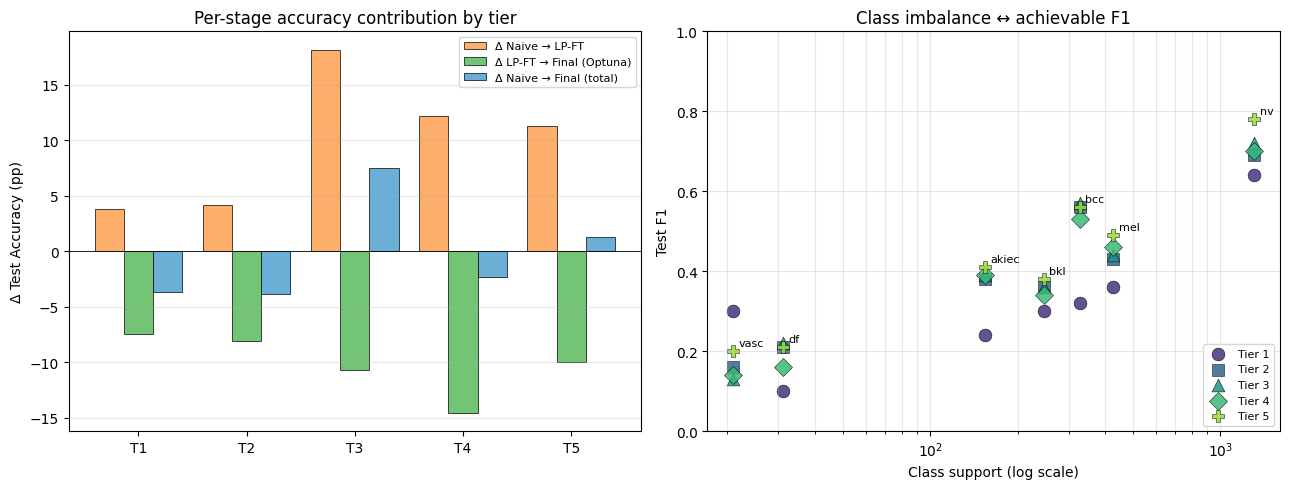

In [25]:
# Class support — citește din test_results dacă există suport per clasă;
# altfel fallback la HAM10000 distribution standard.
def get_class_support():
    """Try to extract per-class support from a final test result."""
    for tier in tiers:
        final = load_final(tier)
        if final and 'overall' in final:
            report = final['overall'].get('classification_report', '')
            sup = {}
            for line in report.split('\n'):
                line = line.strip()
                for cls in CLASS_NAMES:
                    if line.startswith(cls):
                        parts = line.split()
                        if len(parts) >= 5:
                            try:
                                sup[cls] = int(parts[4])
                            except ValueError:
                                pass
            if len(sup) == len(CLASS_NAMES):
                return sup
    # Fallback — HAM10000 official distribution
    return {'akiec': 327, 'bcc': 514, 'bkl': 1099, 'df': 115,
            'mel': 1113, 'nv': 6705, 'vasc': 142}

class_support = get_class_support()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Left: stage deltas ---
ax = axes[0]
naive_to_lpft = [
    (r['lpft_test_acc'] - r['naive_test_acc'])
    if r.get('naive_test_acc') is not None and r.get('lpft_test_acc') is not None else 0
    for r in rows
]
lpft_to_final = [
    (r['final_test_acc'] - r['lpft_test_acc'])
    if r.get('lpft_test_acc') is not None and r.get('final_test_acc') is not None else 0
    for r in rows
]
naive_to_final = [
    (r['final_test_acc'] - r['naive_test_acc'])
    if r.get('naive_test_acc') is not None and r.get('final_test_acc') is not None else 0
    for r in rows
]

x = np.arange(len(tiers))
width = 0.27
ax.bar(x - width, naive_to_lpft, width, label='Δ Naive → LP-FT',
       color='#fdae6b', edgecolor='black', linewidth=0.5)
ax.bar(x,         lpft_to_final, width, label='Δ LP-FT → Final (Optuna)',
       color='#74c476', edgecolor='black', linewidth=0.5)
ax.bar(x + width, naive_to_final, width, label='Δ Naive → Final (total)',
       color='#6baed6', edgecolor='black', linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set_xticks(x)
ax.set_xticklabels([f'T{t}' for t in tiers])
ax.set_ylabel('Δ Test Accuracy (pp)')
ax.set_title('Per-stage accuracy contribution by tier')
ax.legend(fontsize=8)
ax.grid(axis='y', alpha=0.3)

# --- Right: support vs F1 scatter ---
ax = axes[1]
markers = {1: 'o', 2: 's', 3: '^', 4: 'D', 5: 'P'}
colors_t = plt.cm.viridis(np.linspace(0.15, 0.85, len(tiers)))

for i, t in enumerate(tiers):
    final = load_final(t)
    if not final:
        continue
    report = final['overall'].get('classification_report', '')
    pc = parse_classification_report(report)
    xs, ys = [], []
    for c in CLASS_NAMES:
        if c in pc and c in class_support:
            xs.append(class_support[c])
            ys.append(pc[c])
    if xs:
        ax.scatter(xs, ys, marker=markers[t], s=85, color=colors_t[i],
                   edgecolor='black', linewidth=0.4, label=f'Tier {t}', alpha=0.85)

# Annotate class names using the highest tier available
top_tier_pc = None
for t in reversed(tiers):
    final = load_final(t)
    if final:
        top_tier_pc = parse_classification_report(final['overall'].get('classification_report', ''))
        break

if top_tier_pc:
    for c in CLASS_NAMES:
        if c in top_tier_pc and c in class_support:
            ax.annotate(c, (class_support[c], top_tier_pc[c]),
                        xytext=(4, 4), textcoords='offset points', fontsize=8)

ax.set_xscale('log')
ax.set_xlabel('Class support (log scale)')
ax.set_ylabel('Test F1')
ax.set_title('Class imbalance ↔ achievable F1')
ax.set_ylim(0, 1)
ax.legend(fontsize=8, loc='lower right')
ax.grid(alpha=0.3, which='both')

plt.tight_layout()
plt.savefig(SUMMARY_DIR / 'stage_deltas_and_support.png', dpi=150, bbox_inches='tight')
plt.show()


### 7.5 Confusion matrix delta (Tier 5 − Tier 1)

Heatmap diferență între matricea normalizată a Tier 5 și cea a Tier 1. **Verde pe diagonală** = celulă recuperată (mai multe predicții corecte la T5). **Roșu off-diagonală** = erori eliminate. **Roșu pe diagonală sau verde off-diagonală** = regresie.


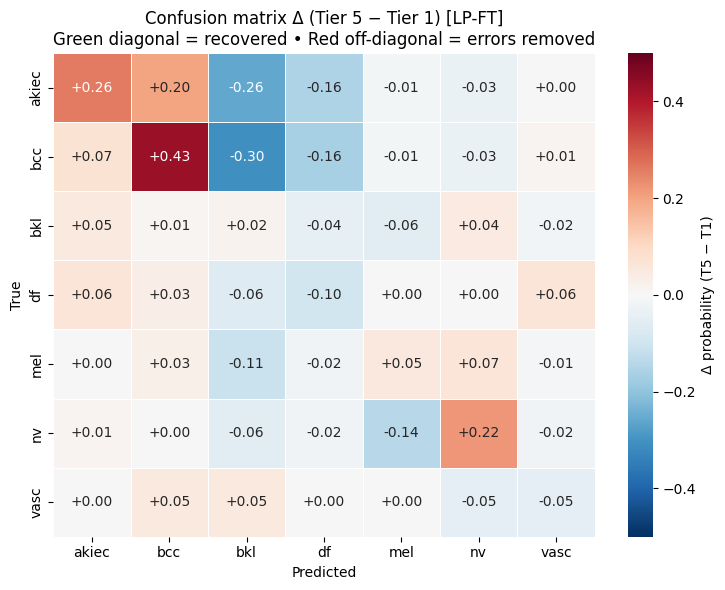

In [26]:
res_t1 = load_lpft(1)
res_t5 = load_lpft(5)

if (res_t1 and res_t5
        and 'confusion_matrix' in res_t1.get('test', {})
        and 'confusion_matrix' in res_t5.get('test', {})):

    cm1 = np.array(res_t1['test']['confusion_matrix'], dtype=float)
    cm5 = np.array(res_t5['test']['confusion_matrix'], dtype=float)

    cm1_norm = cm1 / (cm1.sum(axis=1, keepdims=True) + 1e-9)
    cm5_norm = cm5 / (cm5.sum(axis=1, keepdims=True) + 1e-9)
    delta = cm5_norm - cm1_norm

    fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(delta, annot=True, fmt='+.2f', cmap='RdBu_r', center=0,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cbar_kws={'label': 'Δ probability (T5 − T1)'},
                linewidths=0.4, linecolor='white', ax=ax,
                vmin=-0.5, vmax=0.5)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title('Confusion matrix Δ (Tier 5 − Tier 1) [LP-FT]\n'
                 'Green diagonal = recovered • Red off-diagonal = errors removed')
    plt.tight_layout()
    plt.savefig(SUMMARY_DIR / 'cm_delta_t5_t1.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Need both Tier 1 and Tier 5 LP-FT results with confusion matrices.')

## 8. Concluzii pentru teză

Cu rezultatele de mai sus, capitolul Results al tezei pentru InceptionResNetV2 poate include:

**Master table** — toate metodologiile (Naive / LP-FT / Optuna) × toate tier-urile, cu test accuracy, macro F1, weighted F1, AUC.

**Confusion matrices grid** — vizualizează cum minoritățile (df, vasc) se comportă pe măsură ce crește datele de antrenare.

**Per-source evolution** — povestea principală: cum modelul antrenat doar pe HAM10000 (Tier 1) se descurcă pe BCN_20000 și MSK, vs cum se schimbă când adaugi treptat datele.

**Per-class evolution** — arată dacă focal loss + creșterea datelor recuperează clasele rare.

**Discussion points specifice InceptionResNetV2:**

- **LP-FT depășește final-Optuna pe toate tier-urile** — finding metodologic principal. Pattern invers față de EfficientNetV2B0, unde Optuna a îmbunătățit. Posibilă explicație: spațiul de search Optuna a inclus LR-uri prea mici (1.6e-5 la Tier 5), iar combinația cu focal loss + dense head mai larg (2048 vs 1024 în LP-FT) a dus la val-overfitting fără generalizare.
- **Operational best model = LP-FT**, nu Final. Pentru Grad-CAM și aplicația finală se folosește checkpoint-ul `tier5/B_lpft/best.keras`, nu `tier5/D_final/best.keras`.
- **Naive vs LP-FT**: LP-FT adaugă +4 până la +18 puncte procentuale față de replicarea Nawaz, demonstrând valoarea protocolului în sine.
- **Gap-ul vs paper-ul Nawaz (93% pentru InceptionResNetV2)** — discuție despre split-uri lesion-level vs image-level și despre cele 0 predicții corecte pentru clasa `df` din matricea lor de confuzie (audit forensic).
- **Domain gap HAM → BCN/MSK** rămâne deschis chiar și la Tier 5 — argument pentru limitele transferabilității dermatoscopice cross-instituționale.
- **DF/VASC continuă să fie problematice** — limit fundamental al imbalance-ului, vizibil în scatter plot-ul support↔F1 (secțiunea 7.4).